# Подбор вида зависимости (сравнение регрессий)

**Дисциплина:** Введение в анализ больших данных

Сравниваем три формы связи $y$ и $x$:

1. **Линейная:** $y = a_0 + a_1 x$
2. **Полиномиальная 2-й степени:** $y = a_0 + a_1 x + a_2 x^2$
3. **Логарифмическая:** $y = a_0 + a_1 \log(x)$

Критерии: **MSE**, **AIC**, **Adj. R²**, для вложенных моделей — **ANOVA**, плюс вид остатков.

Демо: «насыщение» урожайности от дозы удобрения (синтетика). Примеры **не из лабораторного задания** — задание выполните на своих данных.


## 0. Импорт


In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(21)


---
## 1. Данные и график

$x$ — доза удобрения, $y$ — урожайность (условные единицы).  
Связь **нелинейная** (насыщение), поэтому линейная модель заведомо слабее.


In [3]:
df = pd.read_csv("water_date.csv")
df.shape


(2244, 6)

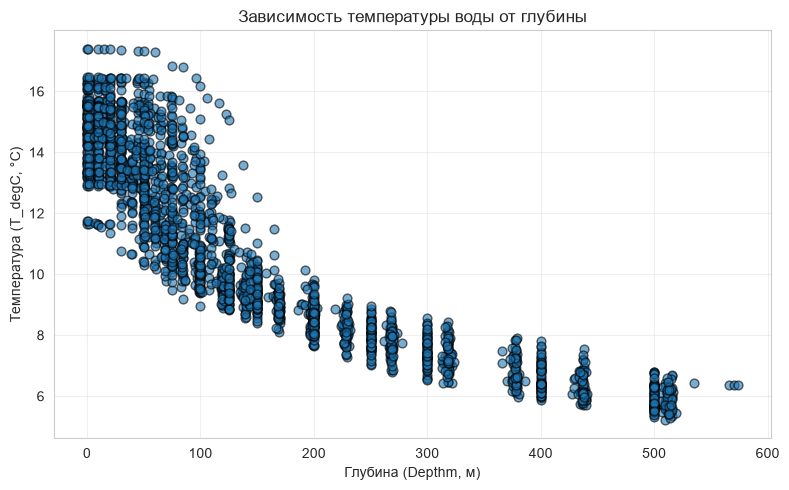

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Depthm"], df["T_degC"], s=40, alpha=0.6, edgecolors="k", zorder=3)
plt.xlabel("Глубина (Depthm, м)")
plt.ylabel("Температура (T_degC, °C)")
plt.title("Зависимость температуры воды от глубины")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## 2. Три модели

| Модель | Формула в `ols` |
|--------|-----------------|
| Линейная | `"yield_ ~ Depthm"` |
| Полином 2 | `"yield_ ~ Depthm + I(Depthm**2)"` |
| Логарифм | `"yield_ ~ np.log(Depthm)"` |

Для логарифма нужно $x > 0$.


In [5]:
df = df[df["Depthm"] > 0].reset_index(drop=True)
df.shape

(2169, 6)

In [7]:
m_lin = smf.ols("T_degC ~ Depthm", data=df).fit()
m_poly = smf.ols("T_degC ~ Depthm + I(Depthm ** 2)", data=df).fit()
m_log = smf.ols("T_degC ~ np.log(Depthm)", data=df).fit()

print("=== Линейная ===")
print(m_lin.summary().tables[1])
print("\n=== Полином 2 ===")
print(m_poly.summary().tables[1])
print("\n=== Логарифмическая ===")
print(m_log.summary().tables[1])


=== Линейная ===
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.7165      0.048    285.262      0.000      13.622      13.811
Depthm        -0.0189      0.000    -85.534      0.000      -0.019      -0.018

=== Полином 2 ===
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         15.0283      0.050    300.108      0.000      14.930      15.126
Depthm            -0.0405      0.001    -69.523      0.000      -0.042      -0.039
I(Depthm ** 2)  4.615e-05   1.19e-06     38.801      0.000    4.38e-05    4.85e-05

=== Логарифмическая ===
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         19.6750      0.125    15

### Вывод
Коэффициенты модели статистически значимы `P>|t|` < 0.05  -> отвергаем нулевую гипотезу (значение t-стат случайно).

`Стандартная ошибка (std err)` низкая, следовательно, t-статистика имеет относительно большие значения - это говорит о том, что коэффициенты модели максимально точны.
`Доверительные интервалы` довольно узкие и не пересекают ноль, значит влияние глубины на температуру присутствует.

Данный вывод применим к каждой модели.

_Отдельное наблюдение:_
В полиноме 2 коэффициент в квадрате, а не просто случайный

### Кривые на одном графике


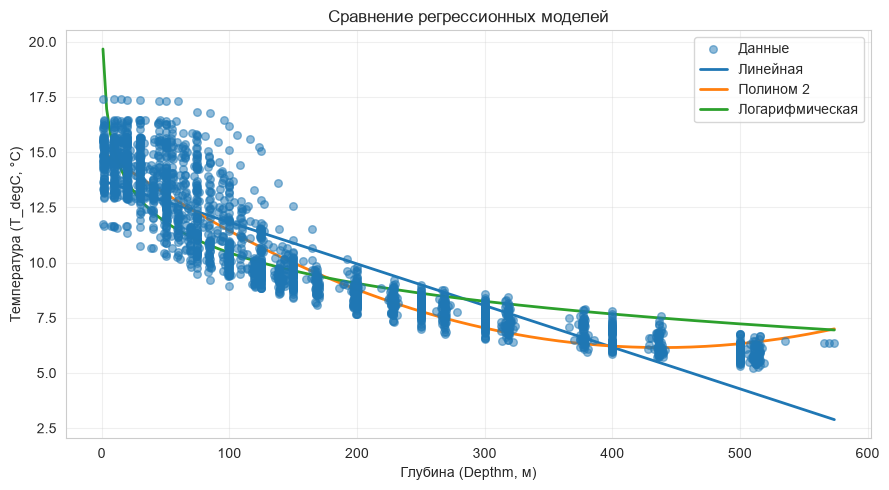

In [20]:
x_grid = np.linspace(df["Depthm"].min(), df["Depthm"].max(), 200)
grid = pd.DataFrame({"Depthm": x_grid})

plt.figure(figsize=(9, 5))
plt.scatter(df["Depthm"], df["T_degC"], s=30, alpha=0.5, label="Данные", zorder=3)

# Предсказания моделей на сетке
plt.plot(x_grid, m_lin.predict(grid), lw=2, label="Линейная")
plt.plot(x_grid, m_poly.predict(grid), lw=2, label="Полином 2")
plt.plot(x_grid, m_log.predict(grid), lw=2, label="Логарифмическая")

plt.xlabel("Глубина (Depthm, м)")
plt.ylabel("Температура (T_degC, °C)")
plt.title("Сравнение регрессионных моделей")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод
Вспоминаем формулы:

| Модель | Формула                      |
|--------|------------------------------|
| Линейная | $$y = a_0 + a_1 x$$          |
| Полином 2 | $$y = a_0 + a_1 x + a_2 x^2$$ |
| Логарифм | $$y = a_0 \log(x)$$                             |

> Если посмотреть на формулы, то график имеет правильный паттерн, в соответствии с формулой. А значит для нашей задачи лучше всего подойдёт **логарифмическая модель**.

Поскольку линейная будет бесконечно снижаться, а полином 2-й степени в моменте разворачивается и бесконечно растёт, то математически для физической задачи подходит логарифмическая модель, ведь она плавно приближается к конкретному значению и на графике видно, что она не снижается.
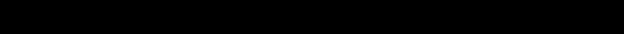

---
## 3. MSE, AIC, Shapiro остатков

- **MSE** = среднее квадратов остатков  
- **AIC** = `model.aic` (баланс между точностью модели (насколько хорошо она описывает данные) и её сложностью (количеством параметров). Чем меньше значение AIC, тем лучше модель.)  
- Shapiro по остаткам — грубая проверка нормальности


In [22]:
def diagnose(model, name):
    resid = model.resid
    mse = np.mean(resid ** 2)
    W, p_sw = stats.shapiro(resid)
    print(f"=== {name} ===")
    print(f"  R²      = {model.rsquared:.4f}")
    print(f"  Adj.R²  = {model.rsquared_adj:.4f}")
    print(f"  MSE     = {mse:.4f}")
    print(f"  AIC     = {model.aic:.2f}")
    print(f"  Shapiro p = {p_sw:.4f}")
    print(f"  Shapiro W = {W:.2f}")
    print()
    return {
        "model": name,
        "R2": model.rsquared,
        "AdjR2": model.rsquared_adj,
        "MSE": mse,
        "AIC": model.aic,
        "Shapiro_p": p_sw,
        "Shapiro_W": W
    }

cmp = pd.DataFrame([
    diagnose(m_lin, "линейная"),
    diagnose(m_poly, "полином 2"),
    diagnose(m_log, "логарифм"),
])
print(cmp.round(4).to_string(index=False))


=== линейная ===
  R²      = 0.7715
  Adj.R²  = 0.7714
  MSE     = 2.2381
  AIC     = 7906.75
  Shapiro p = 0.0000
  Shapiro W = 0.97

=== полином 2 ===
  R²      = 0.8652
  Adj.R²  = 0.8651
  MSE     = 1.3203
  AIC     = 6764.10
  Shapiro p = 0.0000
  Shapiro W = 0.98

=== логарифм ===
  R²      = 0.7219
  Adj.R²  = 0.7218
  MSE     = 2.7239
  AIC     = 8332.86
  Shapiro p = 0.0000
  Shapiro W = 0.94

    model     R2  AdjR2    MSE       AIC  Shapiro_p  Shapiro_W
 линейная 0.7715 0.7714 2.2381 7906.7488        0.0     0.9683
полином 2 0.8652 0.8651 1.3203 6764.1016        0.0     0.9766
 логарифм 0.7219 0.7218 2.7239 8332.8635        0.0     0.9423


### Вывод по метрикам

| Модель | $$R^2$$ | $$Adj.R²$$ | MSE | AIC |
|--------|---------|------------|-----|-----|
| Линейная | 2     | 2          | 2   | 2   |
| Полином 2 | 1    | 1          | 1   | 1   |
| Логарифм | 3     | 3          | 3   | 3   |

Абсолютная победа у Полинома 2-й степени

#### Подробно что значит каждая метрика

$R^2$ - доля дисперсии, которая помогает понять насколько модель лучше монетки. Чем ближе к 1, тем лучше (это процент объяснения всех разбросанных точек), в нашем случае Полином лучше всех "объяснил" дисперсию

$Adj.R^2$ - Скорректированный коэффициент детерминации. Главное отличие $Adj.R^2$ от классического в том, что он имеет штраф за сложность модели.

**MSE(Mean Squared Error)** - средняя квадратичная ошибка, она показывает нам насколько сильно отклоняются предсказанные данные от фактических (метрика качества). Более того, значение ошибки дополнительно возводится в квадрат, чтобы ужесточить штрафы.

AIC (Akaike Information Criterion) - нужен для сравнения моделей по качеству и сложности, например, среди двух одинаковых по качеству моделей выберет ту, у которой меньше параметров. Штрафы помогают в борьбе с переобучением.

Shapiro p и W говорят нам об отсутствии нормальности в остатках




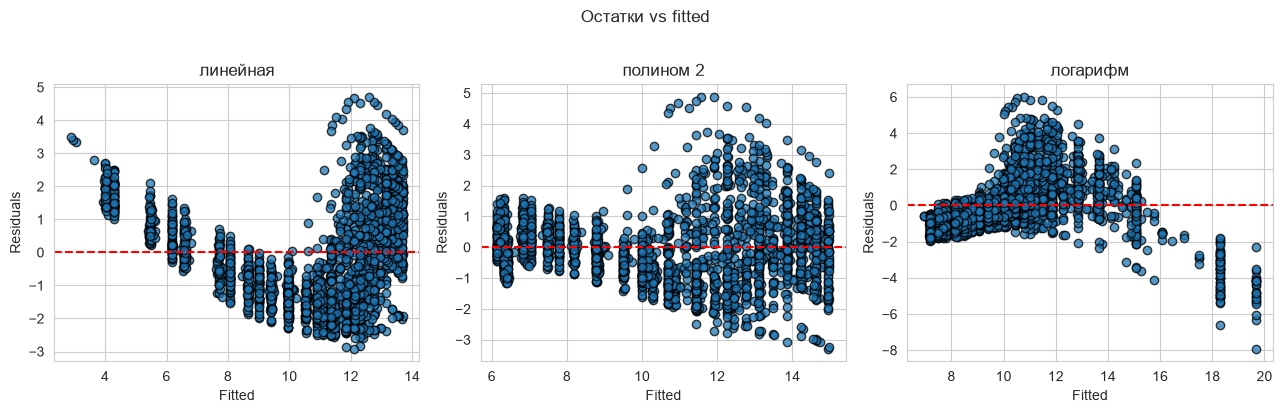

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, model, title in zip(
    axes, [m_lin, m_poly, m_log], ["линейная", "полином 2", "логарифм"]
):
    ax.scatter(model.fittedvalues, model.resid, edgecolors="k", alpha=0.75)
    ax.axhline(0, color="red", ls="--")
    ax.set_xlabel("Fitted")
    ax.set_ylabel("Residuals")
    ax.set_title(title)
plt.suptitle("Остатки vs fitted", y=1.02)
plt.tight_layout()
plt.show()


---
## 4. ANOVA для вложенных моделей

Линейная ⊂ полином 2-й степени.  
`anova_lm(m_lin, m_poly)` проверяет, значимо ли добавление $x^2$.

**df_resid** - Степени свободы остатков (у сложной модели всегда меньше)

**ssr** - Остаточная сумма квадратов. Показывает необъясненную дисперсию.

**df_diff** - Разница в степенях свободы между моделями.

**ss_diff** - Разница в RSS между моделями.

**F** - Значение F-критерия. Чем выше это число, тем значимее вклад новых переменных.

**Pr(>F)** - Вероятность получить такие или еще более выраженные различия между моделями случайно, если на самом деле новые переменные ни на что не влияют.

In [25]:
print("ANOVA: линейная vs полином 2")
print(anova_lm(m_lin, m_poly))
print()
print("Ранжирование по AIC (меньше лучше):")
print(cmp[["model", "AIC", "MSE", "AdjR2"]].sort_values("AIC").to_string(index=False))


ANOVA: линейная vs полином 2
   df_resid          ssr  df_diff      ss_diff            F         Pr(>F)
0    2167.0  4854.411775      0.0          NaN          NaN            NaN
1    2166.0  2863.823231      1.0  1990.588544  1505.545014  1.637352e-250

Ранжирование по AIC (меньше лучше):
    model         AIC      MSE    AdjR2
полином 2 6764.101574 1.320343 0.865066
 линейная 7906.748833 2.238087 0.771381
 логарифм 8332.863468 2.723937 0.721752


---
## 5. Как выбрать модель

1. **AIC** — универсальный критерий (меньше лучше).  
2. **MSE / Adj. R²** — качество подгонки.  
3. **ANOVA** — только для вложенных.  
4. **Остатки** — без тренда и «веера».

Итог по AIC:


In [26]:
best = cmp.loc[cmp["AIC"].idxmin(), "model"]
print(f"По AIC предпочтительна: {best}")
print(cmp.sort_values("AIC")[["model", "AIC", "MSE", "AdjR2"]].round(4).to_string(index=False))


По AIC предпочтительна: полином 2
    model       AIC    MSE  AdjR2
полином 2 6764.1016 1.3203 0.8651
 линейная 7906.7488 2.2381 0.7714
 логарифм 8332.8635 2.7239 0.7218


---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Линейная | `smf.ols("y ~ x", data=df).fit()` |
| Полином 2 | `smf.ols("y ~ x + I(x**2)", data=df).fit()` |
| Логарифм | `smf.ols("y ~ np.log(x)", data=df).fit()` |
| MSE | `np.mean(model.resid**2)` |
| AIC | `model.aic` |
| ANOVA (вложенные) | `anova_lm(m1, m2)` |
| Прогноз на сетке | `model.predict(pd.DataFrame({"x": grid}))` |

---
## Что сделать после лекции

1. Повторите три модели на **других** $x$, $y$ (или своём CSV).
2. Откройте лабораторное задание и сравните модели **самостоятельно**.
3. Для логарифма убедитесь, что $x > 0$.

Удачи!
